# Phase 4: weather-year adjustments

Applies §7 of the Spec: for each region, computes monthly and annual
heating/cooling-degree-day sums, standard (POE50-equivalent) weather, and the
resulting adjustment to `underlying_gwh` / `oper_gwh` implied by the M2 and
M4-long-run coefficients from Phase 3 (`outputs/regression_results.csv`, run
A). This asks how much a weather year's demand would differ from standard
weather, not a forecast or a recommendation (Phase 5).

Reads `data/processed/daily_model_dataset.parquet` and
`outputs/regression_results.csv` (run A rows only) only.

All `net_pct` values in this notebook are percentages (e.g. `1.5` means 1.5%,
not 0.015).

In [1]:
import warnings
warnings.filterwarnings('ignore')

import calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'data' / 'processed' / 'daily_model_dataset.parquet'
REG_PATH = BASE_DIR / 'outputs' / 'regression_results.csv'
OUTPUTS_DIR = BASE_DIR / 'outputs'
FIGURES_DIR = OUTPUTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Akaysha Energy brand colours (docs/examples/monthly_update.ipynb). Inter is
# the documented font but the file is not available in this environment, so
# the matplotlib default font is used instead (as in 03_regressions.ipynb).
AKAYSHA_PINE = '#003723'
AKAYSHA_MOSS = '#00743C'
AKAYSHA_JADE = '#007864'
AKAYSHA_SPRING = '#46C86E'
AKAYSHA_LIME = '#C7F77A'
AKAYSHA_AMARANTH = '#E75751'
AKAYSHA_AMBER = '#F69B4E'
AKAYSHA_AQUA = '#99D9E7'
AKAYSHA_AZURE = '#509EE3'

plt.rcParams.update({
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.edgecolor': '#444444',
    'axes.labelcolor': 'black',
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'grid.color': '#DDDDDD',
    'grid.linewidth': 0.6,
    'axes.grid': True,
    'axes.axisbelow': True,
    'font.size': 10,
})

REGIONS = ['NSW1', 'QLD1', 'SA1', 'TAS1', 'VIC1']
REGION_COLOR = {
    'NSW1': AKAYSHA_PINE,
    'QLD1': AKAYSHA_AMBER,
    'SA1': AKAYSHA_AZURE,
    'TAS1': AKAYSHA_AMARANTH,
    'VIC1': AKAYSHA_SPRING,
}
# Weather years (complete calendar years), per Spec S7.
REGION_YEARS = {
    'NSW1': (2008, 2025), 'QLD1': (2008, 2025),
    'SA1': (2001, 2025), 'TAS1': (2001, 2025), 'VIC1': (2001, 2025),
}
PRIMARY = ('2022-09-01', '2026-08-31')  # run A primary window, S6/S7
DEP_VARS = ['underlying_gwh', 'oper_gwh']
DEP_OK = {'underlying_gwh': 'ok_underlying', 'oper_gwh': 'ok_oper'}
COEF_SETS = ['M2', 'M4_LR']
COEF_SET_COLOR = {'M2': AKAYSHA_PINE, 'M4_LR': AKAYSHA_AMBER}

df = pd.read_parquet(DATA_PATH)
df['date'] = pd.to_datetime(df['date'].astype(str), format='%Y-%m-%d')
assert set(df['region'].unique()) == set(REGIONS)
print(df.shape, df['date'].min().date(), '->', df['date'].max().date())

(46870, 38) 2001-01-01 -> 2026-08-31


## Coefficients (run A, M2 and M4 long-run)

`M2` beta = `b_HDD`, `b_CDD` from the run A `model == 'M2'` row.
`M4_LR` beta = `b_HDD_LR`, `b_CDD_LR` from the run A `model == 'M4'` row.
Both for `dep_var` in `{underlying_gwh, oper_gwh}`, window
2022-09-01 -> 2026-08-31. Betas are used as estimated (TAS1 CDD not zeroed
out).

In [2]:
reg = pd.read_csv(REG_PATH)
regA = reg[reg['run_id'] == 'A'].copy()
regA['window_start'] = pd.to_datetime(regA['window_start']).dt.date
regA['window_end'] = pd.to_datetime(regA['window_end']).dt.date
ps, pe = pd.Timestamp(PRIMARY[0]).date(), pd.Timestamp(PRIMARY[1]).date()
regA = regA[(regA['window_start'] == ps) & (regA['window_end'] == pe)]

chk = regA.groupby(['region', 'model', 'dep_var']).size()
assert (chk == 1).all(), f'expected exactly one row per (region, model, dep_var): {chk[chk != 1]}'
assert set(regA['region']) == set(REGIONS)
assert set(regA['model']) == {'M1', 'M2', 'M3', 'M4'}

coef = {}
for region in REGIONS:
    for dep_var in DEP_VARS:
        m2 = regA[(regA.region == region) & (regA.model == 'M2') & (regA.dep_var == dep_var)].iloc[0]
        m4 = regA[(regA.region == region) & (regA.model == 'M4') & (regA.dep_var == dep_var)].iloc[0]
        coef[(region, dep_var, 'M2')] = (float(m2['b_HDD']), float(m2['b_CDD']))
        coef[(region, dep_var, 'M4_LR')] = (float(m4['b_HDD_LR']), float(m4['b_CDD_LR']))

coef_table = pd.DataFrame([
    {'region': r, 'dep_var': dv, 'coef_set': cs, 'b_HDD': coef[(r, dv, cs)][0], 'b_CDD': coef[(r, dv, cs)][1]}
    for r in REGIONS for dv in DEP_VARS for cs in COEF_SETS
])
coef_table

,region,dep_var,coef_set,b_HDD,b_CDD
0,NSW1,underlying_gwh,M2,4.088610,8.145689
1,NSW1,underlying_gwh,M4_LR,4.561232,8.578502
2,NSW1,oper_gwh,M2,3.844807,6.963465
3,NSW1,oper_gwh,M4_LR,4.310357,7.823216
4,QLD1,underlying_gwh,M2,1.621657,6.379317
5,QLD1,underlying_gwh,M4_LR,1.843421,6.650219
6,QLD1,oper_gwh,M2,0.998219,5.387529
7,QLD1,oper_gwh,M4_LR,1.369042,6.147302
8,SA1,underlying_gwh,M2,0.649728,1.790870
9,SA1,underlying_gwh,M4_LR,0.755365,1.930134


## Monthly degree-day sums (S7)

A region-month is valid if >= 90% of its days have `ok_temp`. For valid
months, `HDD_m = mean(daily HDD over ok_temp days) x calendar days in month`
(CDD identical). Invalid months are NaN. `valid_day_share` is recorded for
every month. Degree days do not depend on `dep_var` or `coef_set`, so this is
computed once per region.

In [3]:
dd_rows = []
for region in REGIONS:
    rdf = df[df.region == region]
    start_y, end_y = REGION_YEARS[region]
    for year in range(start_y, end_y + 1):
        for month in range(1, 13):
            sub = rdf[(rdf.year == year) & (rdf.month == month)]
            days_in_month = calendar.monthrange(year, month)[1]
            assert len(sub) == days_in_month, (region, year, month, len(sub), days_in_month)
            n_valid = int(sub['ok_temp'].sum())
            valid_share = n_valid / days_in_month
            if valid_share >= 0.90:
                hdd_m = sub.loc[sub.ok_temp, 'HDD'].mean() * days_in_month
                cdd_m = sub.loc[sub.ok_temp, 'CDD'].mean() * days_in_month
            else:
                hdd_m = np.nan
                cdd_m = np.nan
            dd_rows.append({'region': region, 'year': year, 'month': month,
                             'valid_day_share': valid_share, 'HDD': hdd_m, 'CDD': cdd_m})
dd_df = pd.DataFrame(dd_rows)
print('region-months:', dd_df.shape[0], '  invalid months by region:')
print(dd_df[dd_df.HDD.isna()].groupby('region').size())

region-months: 1332   invalid months by region:
region
NSW1     8
QLD1     1
SA1      5
TAS1    20
VIC1     2
dtype: int64


## Valid weather years and standard weather (S7)

A weather year (CY) is valid if all 12 months are valid. `std_HDD_m` /
`std_CDD_m` = mean of month-m sums over valid CY weather years only (valid
months in otherwise-invalid years do not enter the standard). The annual
standard is `sum_m std_m`. The same monthly standards feed both the CY and FY
roll-ups (orchestrator clarification #3).

Valid FY years (labelled by ending year) are separately determined: a FY is
valid if all 12 of its months (Jul(Y-1)..Jun(Y)) are individually valid *and*
both straddled calendar years lie inside the region's CY range (clarification
#6).

In [4]:
valid_cy = {}
invalid_cy_reasons = {}
for region in REGIONS:
    g = dd_df[dd_df.region == region]
    year_valid = g.groupby('year')['HDD'].apply(lambda s: s.notna().all())
    valid_cy[region] = sorted(year_valid[year_valid].index.tolist())
    invalid_years = sorted(year_valid[~year_valid].index.tolist())
    reasons = {}
    for y in invalid_years:
        reasons[y] = g[(g.year == y) & (g.HDD.isna())]['month'].tolist()
    invalid_cy_reasons[region] = reasons
    print(f'{region}: {len(valid_cy[region])} valid CY years of {len(g.year.unique())}; '
          f'excluded {reasons}')

std = {}
annual_std = {}
for region in REGIONS:
    g = dd_df[(dd_df.region == region) & (dd_df.year.isin(valid_cy[region]))]
    sm = g.groupby('month')[['HDD', 'CDD']].mean()
    for m in range(1, 13):
        std[(region, m)] = (sm.loc[m, 'HDD'], sm.loc[m, 'CDD'])
    annual_std[region] = (sm['HDD'].sum(), sm['CDD'].sum())

median_cy = {}
for region in REGIONS:
    g = dd_df[(dd_df.region == region) & (dd_df.year.isin(valid_cy[region]))]
    annual_totals = g.groupby('year')[['HDD', 'CDD']].sum()
    median_cy[region] = (annual_totals['HDD'].median(), annual_totals['CDD'].median())

valid_fy = {}
fy_totals_cache = {}
for region in REGIONS:
    start_y, end_y = REGION_YEARS[region]
    g = dd_df[dd_df.region == region].set_index(['year', 'month'])
    fy_list, fy_tot = [], {}
    for Y in range(start_y + 1, end_y + 1):
        if Y - 1 < start_y or Y > end_y:
            continue
        months = [(Y - 1, m) for m in range(7, 13)] + [(Y, m) for m in range(1, 7)]
        rows = g.loc[months]
        if rows['HDD'].isna().any():
            continue
        fy_list.append(Y)
        fy_tot[Y] = (rows['HDD'].sum(), rows['CDD'].sum())
    valid_fy[region] = fy_list
    fy_totals_cache[region] = fy_tot
    print(f'{region}: {len(fy_list)} valid FY years, FY{fy_list[0]}..FY{fy_list[-1]}')

median_fy = {}
for region in REGIONS:
    tot = fy_totals_cache[region]
    median_fy[region] = (np.median([v[0] for v in tot.values()]), np.median([v[1] for v in tot.values()]))

std_table = pd.DataFrame([
    {'region': r, 'annual_std_HDD': annual_std[r][0], 'annual_std_CDD': annual_std[r][1],
     'median_cy_HDD': median_cy[r][0], 'median_cy_CDD': median_cy[r][1],
     'median_fy_HDD': median_fy[r][0], 'median_fy_CDD': median_fy[r][1]}
    for r in REGIONS
])
std_table

NSW1: 13 valid CY years of 18; excluded {2008: [9, 10], 2010: [4, 5], 2016: [2, 8], 2017: [9], 2024: [8]}
QLD1: 17 valid CY years of 18; excluded {2016: [8]}
SA1: 22 valid CY years of 25; excluded {2001: [7, 10, 12], 2002: [8], 2003: [9]}
TAS1: 20 valid CY years of 25; excluded {2001: [1, 2, 4, 6, 7, 8, 9, 12], 2002: [6, 9, 10, 11, 12], 2003: [6, 8, 9, 12], 2004: [1, 2], 2014: [6]}
VIC1: 23 valid CY years of 25; excluded {2001: [7], 2010: [3]}
NSW1: 11 valid FY years, FY2011..FY2024
QLD1: 16 valid FY years, FY2009..FY2025
SA1: 21 valid FY years, FY2005..FY2025
TAS1: 20 valid FY years, FY2005..FY2025
VIC1: 22 valid FY years, FY2003..FY2025


,region,annual_std_HDD,annual_std_CDD,median_cy_HDD,median_cy_CDD,median_fy_HDD,median_fy_CDD
0,NSW1,636.241277,208.037875,629.616667,218.341667,649.655409,197.605455
1,QLD1,221.477638,368.224873,219.100222,379.774208,215.846315,373.319087
2,SA1,667.247627,288.410005,664.939738,289.175469,656.424819,276.484158
3,TAS1,1316.151057,28.527996,1323.060816,27.499429,1316.117469,30.754083
4,VIC1,819.182588,143.742208,830.575485,153.629167,823.995926,144.429525


## Denominators (orchestrator clarification #5)

Monthly denominator = mean daily dep-var energy for calendar month *m* over
primary-window days with the dep-var ok flag True, x calendar days in month
*m* of the weather year (so leap-year Februaries get 29 days). Annual
denominator = mean daily dep-var energy over all ok primary-window days x
365.25 (same denominator for CY and FY).

In [5]:
monthly_denom_mean = {}   # (region, dep_var, month) -> mean daily energy, primary window
annual_denom_mean = {}    # (region, dep_var) -> mean daily energy, primary window

for region in REGIONS:
    rdf = df[df.region == region]
    prim = rdf[(rdf.date >= pd.Timestamp(PRIMARY[0])) & (rdf.date <= pd.Timestamp(PRIMARY[1]))]
    for dep_var in DEP_VARS:
        okcol = DEP_OK[dep_var]
        ok_prim = prim[prim[okcol]]
        annual_denom_mean[(region, dep_var)] = ok_prim[dep_var].mean() * 365.25
        for m in range(1, 13):
            monthly_denom_mean[(region, dep_var, m)] = ok_prim[ok_prim.month == m][dep_var].mean()

denom_table = pd.DataFrame([
    {'region': r, 'dep_var': dv, 'annual_denom_gwh': annual_denom_mean[(r, dv)]}
    for r in REGIONS for dv in DEP_VARS
])
print(denom_table.to_string(index=False))
print()
print('Monthly mean-daily-energy denominators (GWh/day), underlying_gwh:')
print(pd.Series({m: monthly_denom_mean[('NSW1', 'underlying_gwh', m)] for m in range(1, 13)}, name='NSW1'))

region        dep_var  annual_denom_gwh
  NSW1 underlying_gwh      75114.170694
  NSW1       oper_gwh      66388.138454
  QLD1 underlying_gwh      62599.569192
  QLD1       oper_gwh      54102.520907
   SA1 underlying_gwh      14580.653490
   SA1       oper_gwh      11435.969870
  TAS1 underlying_gwh      10428.471938
  TAS1       oper_gwh      10043.673395
  VIC1 underlying_gwh      49459.836312
  VIC1       oper_gwh      43956.447173

Monthly mean-daily-energy denominators (GWh/day), underlying_gwh:
1     208.643684
2     215.498928
3     205.535179
4     188.584701
5     203.446839
6     222.401443
7     224.880203
8     214.069542
9     195.235130
10    189.730057
11    195.248497
12    204.701900
Name: NSW1, dtype: float64


## `weather_year_monthly.csv`

One row per (region, dep_var, coef_set, weather_year, month) for every weather
year in the region's S7 range, including invalid months (NaN adjustments,
`valid_day_share` filled) and valid months in otherwise-invalid years
(adjustments computed against the standard).

In [6]:
rows = []
for region in REGIONS:
    start_y, end_y = REGION_YEARS[region]
    ddg = dd_df[dd_df.region == region].set_index(['year', 'month'])
    for year in range(start_y, end_y + 1):
        for month in range(1, 13):
            r = ddg.loc[(year, month)]
            valid_share = r['valid_day_share']
            hdd_m, cdd_m = r['HDD'], r['CDD']
            std_hdd, std_cdd = std[(region, month)]
            days_in_month = calendar.monthrange(year, month)[1]
            for dep_var in DEP_VARS:
                denom = monthly_denom_mean[(region, dep_var, month)] * days_in_month
                for coef_set in COEF_SETS:
                    b_hdd, b_cdd = coef[(region, dep_var, coef_set)]
                    if pd.isna(hdd_m):
                        heat_adj = cool_adj = net_adj = net_pct = np.nan
                    else:
                        heat_adj = b_hdd * (hdd_m - std_hdd)
                        cool_adj = b_cdd * (cdd_m - std_cdd)
                        net_adj = heat_adj + cool_adj
                        net_pct = net_adj / denom * 100
                    rows.append({
                        'region': region, 'dep_var': dep_var, 'coef_set': coef_set,
                        'weather_year': year, 'month': month,
                        'valid_day_share': valid_share, 'HDD': hdd_m, 'CDD': cdd_m,
                        'std_HDD': std_hdd, 'std_CDD': std_cdd,
                        'heat_adj_gwh': heat_adj, 'cool_adj_gwh': cool_adj,
                        'net_adj_gwh': net_adj, 'net_pct': net_pct,
                    })

monthly_df = pd.DataFrame(rows)
monthly_df.to_csv(OUTPUTS_DIR / 'weather_year_monthly.csv', index=False)
print(monthly_df.shape)
monthly_df.head()

(5328, 14)


,region,dep_var,coef_set,weather_year,month,valid_day_share,HDD,CDD,std_HDD,std_CDD,heat_adj_gwh,cool_adj_gwh,net_adj_gwh,net_pct
0,NSW1,underlying_gwh,M2,2008,1,0.935484,0.000000,43.853826,0.038301,71.800662,-0.156599,-227.646233,-227.802832,-3.522023
1,NSW1,underlying_gwh,M4_LR,2008,1,0.935484,0.000000,43.853826,0.038301,71.800662,-0.174701,-239.741981,-239.916682,-3.709313
2,NSW1,oper_gwh,M2,2008,1,0.935484,0.000000,43.853826,0.038301,71.800662,-0.147261,-194.606810,-194.754071,-3.504096
3,NSW1,oper_gwh,M4_LR,2008,1,0.935484,0.000000,43.853826,0.038301,71.800662,-0.165092,-218.634133,-218.799225,-3.936726
4,NSW1,underlying_gwh,M2,2008,2,1.000000,0.629787,6.913874,0.024199,43.634511,2.476015,-299.114885,-296.638870,-4.746625


## `weather_year_annual.csv`: CY and FY roll-ups

Only complete years (all 12 months valid) are written; invalid years are
omitted, not filled with NaN (orchestrator clarification #6/#7).
`std_HDD`/`std_CDD` = the annual standard (same for CY and FY). `median_HDD`/
`median_CDD` = median of the annual totals over valid years *of that
year_type*.

In [7]:
annual_rows = []
for region in REGIONS:
    for dep_var in DEP_VARS:
        denom = annual_denom_mean[(region, dep_var)]
        for coef_set in COEF_SETS:
            for year in valid_cy[region]:
                sub = monthly_df[(monthly_df.region == region) & (monthly_df.dep_var == dep_var)
                                  & (monthly_df.coef_set == coef_set) & (monthly_df.weather_year == year)]
                assert len(sub) == 12 and sub['HDD'].notna().all()
                hdd, cdd = sub['HDD'].sum(), sub['CDD'].sum()
                heat, cool = sub['heat_adj_gwh'].sum(), sub['cool_adj_gwh'].sum()
                net = heat + cool
                annual_rows.append({
                    'region': region, 'dep_var': dep_var, 'coef_set': coef_set,
                    'year_type': 'CY', 'year': year, 'HDD': hdd, 'CDD': cdd,
                    'std_HDD': annual_std[region][0], 'std_CDD': annual_std[region][1],
                    'median_HDD': median_cy[region][0], 'median_CDD': median_cy[region][1],
                    'heat_adj_gwh': heat, 'cool_adj_gwh': cool, 'net_adj_gwh': net,
                    'net_pct': net / denom * 100,
                })
            for year in valid_fy[region]:
                months = [(year - 1, m) for m in range(7, 13)] + [(year, m) for m in range(1, 7)]
                sub_frames = []
                for (yy, mm) in months:
                    s = monthly_df[(monthly_df.region == region) & (monthly_df.dep_var == dep_var)
                                    & (monthly_df.coef_set == coef_set) & (monthly_df.weather_year == yy)
                                    & (monthly_df.month == mm)]
                    assert len(s) == 1
                    sub_frames.append(s)
                sub = pd.concat(sub_frames)
                assert sub['HDD'].notna().all()
                hdd, cdd = sub['HDD'].sum(), sub['CDD'].sum()
                heat, cool = sub['heat_adj_gwh'].sum(), sub['cool_adj_gwh'].sum()
                net = heat + cool
                annual_rows.append({
                    'region': region, 'dep_var': dep_var, 'coef_set': coef_set,
                    'year_type': 'FY', 'year': year, 'HDD': hdd, 'CDD': cdd,
                    'std_HDD': annual_std[region][0], 'std_CDD': annual_std[region][1],
                    'median_HDD': median_fy[region][0], 'median_CDD': median_fy[region][1],
                    'heat_adj_gwh': heat, 'cool_adj_gwh': cool, 'net_adj_gwh': net,
                    'net_pct': net / denom * 100,
                })

annual_df = pd.DataFrame(annual_rows)
annual_df.to_csv(OUTPUTS_DIR / 'weather_year_annual.csv', index=False)
print(annual_df.shape)
annual_df[(annual_df.region == 'NSW1') & (annual_df.dep_var == 'underlying_gwh') & (annual_df.coef_set == 'M2')]

(740, 15)


,region,dep_var,coef_set,year_type,year,HDD,CDD,std_HDD,std_CDD,median_HDD,median_CDD,heat_adj_gwh,cool_adj_gwh,net_adj_gwh,net_pct
0,NSW1,underlying_gwh,M2,CY,2009,639.828234,235.260744,636.241277,208.037875,629.616667,218.341667,14.665671,221.749027,236.414698,0.314740
1,NSW1,underlying_gwh,M2,CY,2011,735.879991,226.423398,636.241277,208.037875,629.616667,218.341667,407.383831,149.762754,557.146585,0.741733
2,NSW1,underlying_gwh,M2,CY,2012,753.298535,126.569909,636.241277,208.037875,629.616667,218.341667,478.601461,-663.612717,-185.011256,-0.246307
3,NSW1,underlying_gwh,M2,CY,2013,552.933215,210.019256,636.241277,208.037875,629.616667,218.341667,-340.614159,16.139708,-324.474451,-0.431975
4,NSW1,underlying_gwh,M2,CY,2014,594.753341,175.516233,636.241277,208.037875,629.616667,218.341667,-169.627982,-264.911182,-434.539164,-0.578505
5,NSW1,underlying_gwh,M2,CY,2015,677.379753,210.001040,636.241277,208.037875,629.616667,218.341667,168.199178,15.991330,184.190508,0.245214
6,NSW1,underlying_gwh,M2,CY,2018,659.303256,274.565688,636.241277,208.037875,629.616667,218.341667,94.291436,541.914873,636.206309,0.846986
7,NSW1,underlying_gwh,M2,CY,2019,592.706349,294.016810,636.241277,208.037875,629.616667,218.341667,-177.997332,700.357667,522.360336,0.695422
8,NSW1,underlying_gwh,M2,CY,2020,601.312500,220.172917,636.241277,208.037875,629.616667,218.341667,-142.810140,98.848274,-43.961865,-0.058527
9,NSW1,underlying_gwh,M2,CY,2021,653.067374,131.333333,636.241277,208.037875,629.616667,218.341667,68.795347,-624.811343,-556.015996,-0.740228


## `materiality_summary.csv`

Per (region, dep_var, coef_set): annual `net_pct` min/max/range (CY and FY),
the share of valid region-months with `|net_pct| > 5%` and `> 2.5%` (strict,
over valid months only, including valid months inside otherwise-invalid
years), and the mean-minus-median offset in degree-days and in the implied
`net_pct` (the % shift that AEMO's POE50/median convention implies relative to
the mean-based standard used here). All percentages are expressed as e.g.
`1.5` for 1.5%.

In [8]:
n_valid_months_region = dd_df.groupby('region')['HDD'].apply(lambda s: s.notna().sum()).to_dict()

summary_rows = []
for region in REGIONS:
    for dep_var in DEP_VARS:
        for coef_set in COEF_SETS:
            cy = annual_df[(annual_df.region == region) & (annual_df.dep_var == dep_var)
                            & (annual_df.coef_set == coef_set) & (annual_df.year_type == 'CY')]
            fy = annual_df[(annual_df.region == region) & (annual_df.dep_var == dep_var)
                            & (annual_df.coef_set == coef_set) & (annual_df.year_type == 'FY')]
            mm = monthly_df[(monthly_df.region == region) & (monthly_df.dep_var == dep_var)
                             & (monthly_df.coef_set == coef_set) & monthly_df.net_pct.notna()]
            n_valid_m = len(mm)
            assert n_valid_m == n_valid_months_region[region]
            b_hdd, b_cdd = coef[(region, dep_var, coef_set)]
            offset_hdd = annual_std[region][0] - median_cy[region][0]
            offset_cdd = annual_std[region][1] - median_cy[region][1]
            fy_offset_hdd = annual_std[region][0] - median_fy[region][0]
            fy_offset_cdd = annual_std[region][1] - median_fy[region][1]
            denom = annual_denom_mean[(region, dep_var)]
            summary_rows.append({
                'region': region, 'dep_var': dep_var, 'coef_set': coef_set,
                'cy_net_pct_min': cy['net_pct'].min(), 'cy_net_pct_max': cy['net_pct'].max(),
                'cy_net_pct_range': cy['net_pct'].max() - cy['net_pct'].min(),
                'fy_net_pct_min': fy['net_pct'].min(), 'fy_net_pct_max': fy['net_pct'].max(),
                'fy_net_pct_range': fy['net_pct'].max() - fy['net_pct'].min(),
                'n_cy_years': len(cy), 'n_fy_years': len(fy), 'n_valid_months': n_valid_m,
                'share_months_abs_gt_5pct': (mm['net_pct'].abs() > 5).sum() / n_valid_m,
                'share_months_abs_gt_2p5pct': (mm['net_pct'].abs() > 2.5).sum() / n_valid_m,
                'cy_offset_HDD': offset_hdd, 'cy_offset_CDD': offset_cdd,
                'fy_offset_HDD': fy_offset_hdd, 'fy_offset_CDD': fy_offset_cdd,
                'cy_offset_net_pct': (b_hdd * offset_hdd + b_cdd * offset_cdd) / denom * 100,
                'fy_offset_net_pct': (b_hdd * fy_offset_hdd + b_cdd * fy_offset_cdd) / denom * 100,
            })

materiality_summary = pd.DataFrame(summary_rows)
materiality_summary.to_csv(OUTPUTS_DIR / 'materiality_summary.csv', index=False)
pd.set_option('display.width', 200)
materiality_summary

,region,dep_var,coef_set,cy_net_pct_min,cy_net_pct_max,cy_net_pct_range,fy_net_pct_min,fy_net_pct_max,fy_net_pct_range,n_cy_years,n_fy_years,n_valid_months,share_months_abs_gt_5pct,share_months_abs_gt_2p5pct,cy_offset_HDD,cy_offset_CDD,fy_offset_HDD,fy_offset_CDD,cy_offset_net_pct,fy_offset_net_pct
0,NSW1,underlying_gwh,M2,-1.006920,0.846986,1.853906,-1.099903,1.052269,2.152172,13,11,208,0.028846,0.129808,6.624610,-10.303792,-13.414132,10.432420,-0.075680,0.040118
1,NSW1,underlying_gwh,M4_LR,-1.062674,0.899830,1.962504,-1.205331,1.112740,2.318071,13,11,208,0.028846,0.158654,6.624610,-10.303792,-13.414132,10.432420,-0.077448,0.037689
2,NSW1,oper_gwh,M2,-0.977410,0.831373,1.808783,-1.136631,1.024848,2.161479,13,11,208,0.028846,0.134615,6.624610,-10.303792,-13.414132,10.432420,-0.069711,0.031739
3,NSW1,oper_gwh,M4_LR,-1.097995,0.933701,2.031697,-1.275061,1.151197,2.426258,13,11,208,0.033654,0.173077,6.624610,-10.303792,-13.414132,10.432420,-0.078409,0.035843
4,QLD1,underlying_gwh,M2,-1.241440,1.274656,2.516096,-1.153044,0.895678,2.048721,17,16,215,0.013953,0.139535,2.377416,-11.549335,5.631323,-5.094214,-0.111537,-0.037325
5,QLD1,underlying_gwh,M4_LR,-1.279943,1.315388,2.595331,-1.188760,0.927703,2.116463,17,16,215,0.013953,0.162791,2.377416,-11.549335,5.631323,-5.094214,-0.115693,-0.037535
6,QLD1,oper_gwh,M2,-1.253038,1.283199,2.536237,-1.163946,0.892116,2.056062,17,16,215,0.013953,0.139535,2.377416,-11.549335,5.631323,-5.094214,-0.110622,-0.040338
7,QLD1,oper_gwh,M4_LR,-1.405000,1.440839,2.845839,-1.305026,1.007463,2.312489,17,16,215,0.023256,0.167442,2.377416,-11.549335,5.631323,-5.094214,-0.125211,-0.043632
8,SA1,underlying_gwh,M2,-1.894615,1.843771,3.738386,-1.240237,1.329081,2.569318,22,21,295,0.071186,0.240678,2.307889,-0.765464,10.822808,11.925846,0.000882,0.194707
9,SA1,underlying_gwh,M4_LR,-2.074124,2.000939,4.075062,-1.341400,1.426507,2.767907,22,21,295,0.098305,0.267797,2.307889,-0.765464,10.822808,11.925846,0.001823,0.213939


## Figures

Consulted the `dataviz` skill before writing this section. Both figures reuse
fixed, mutually-distinct Akaysha categorical colours assigned by identity
(region, or `coef_set`), never re-cycled. The heatmap uses a genuine two-hue
diverging palette (AZURE cool pole -> white neutral -> AMARANTH warm pole)
built from the Akaysha constants, with a neutral grey for invalid months
(never a rainbow, never a hue at the midpoint), and one shared, symmetric
colour scale across all five region facets.

### `annual_adjustment.png`: CY net % by weather year, M2 vs M4_LR, underlying_gwh only

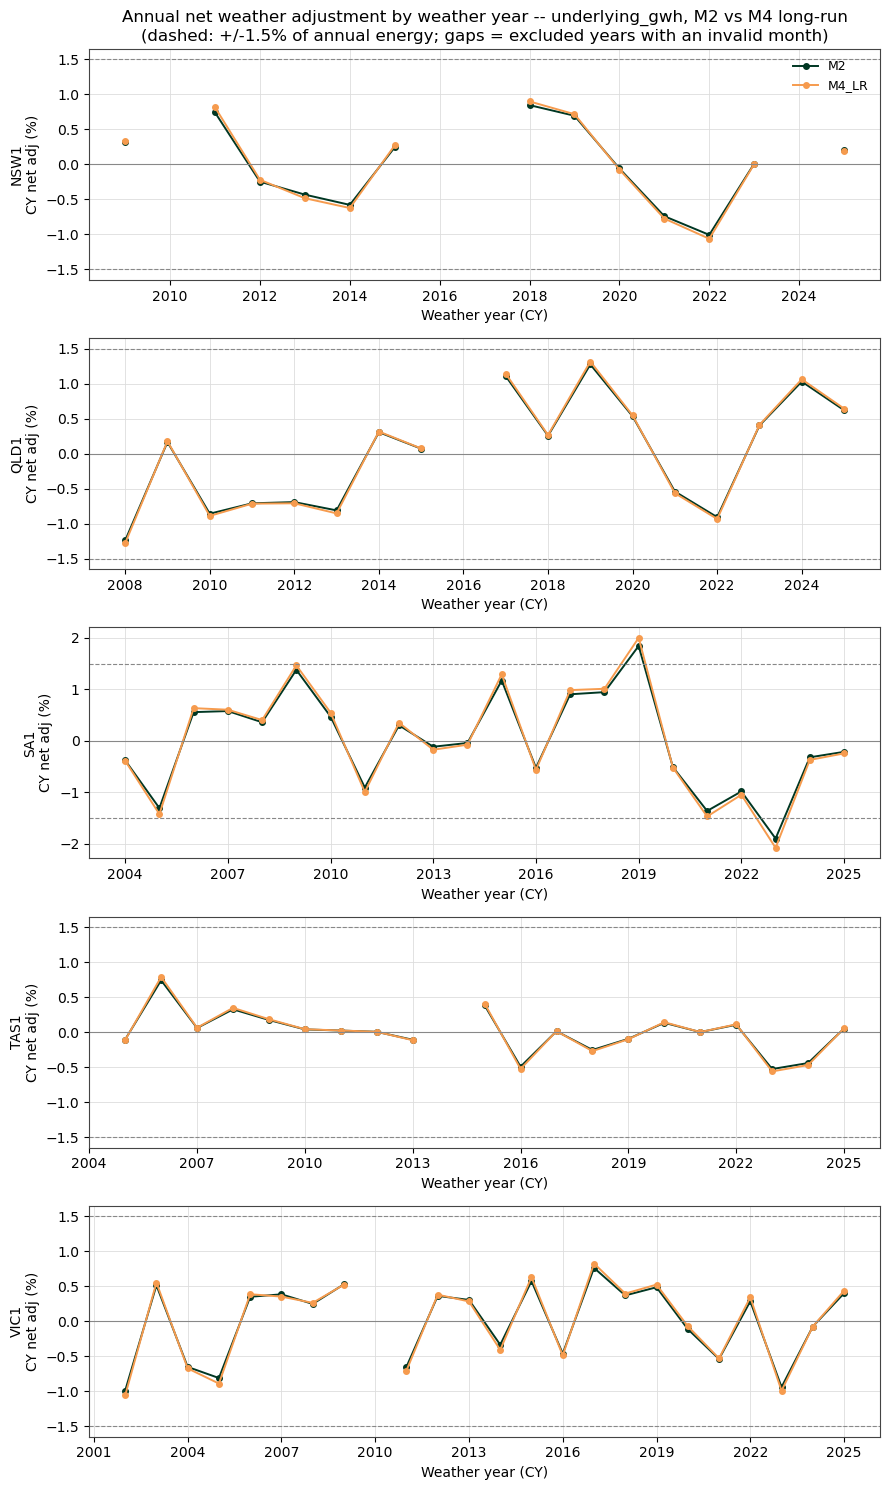

In [9]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(len(REGIONS), 1, figsize=(9, 3.0 * len(REGIONS)), sharex=False)

for ax, region in zip(axes, REGIONS):
    for coef_set in COEF_SETS:
        sub = annual_df[(annual_df.region == region) & (annual_df.dep_var == 'underlying_gwh')
                         & (annual_df.coef_set == coef_set) & (annual_df.year_type == 'CY')]
        # Reindex to every weather year so excluded (invalid) years break the line instead of being bridged.
        sub = sub.set_index('year').reindex(range(REGION_YEARS[region][0], REGION_YEARS[region][1] + 1)).reset_index()
        ax.plot(sub['year'], sub['net_pct'], marker='o', markersize=4, linewidth=1.4,
                color=COEF_SET_COLOR[coef_set], label=coef_set)
    ax.axhline(0, color='#888888', linewidth=0.8)
    ax.axhline(1.5, color='#888888', linewidth=0.8, linestyle='--')
    ax.axhline(-1.5, color='#888888', linewidth=0.8, linestyle='--')
    ax.set_ylabel(f'{region}\nCY net adj (%)')
    ax.set_xlabel('Weather year (CY)')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

axes[0].set_title('Annual net weather adjustment by weather year -- underlying_gwh, M2 vs M4 long-run\n(dashed: +/-1.5% of annual energy; gaps = excluded years with an invalid month)')
axes[0].legend(frameon=False, loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'annual_adjustment.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

### `monthly_heatmap.png`: month x weather-year net %, underlying_gwh / M2 only

Invalid months are shown as light grey (`set_bad`), noted in the caption.

max |net_pct|: 13.89 -> colour scale capped at 10.0


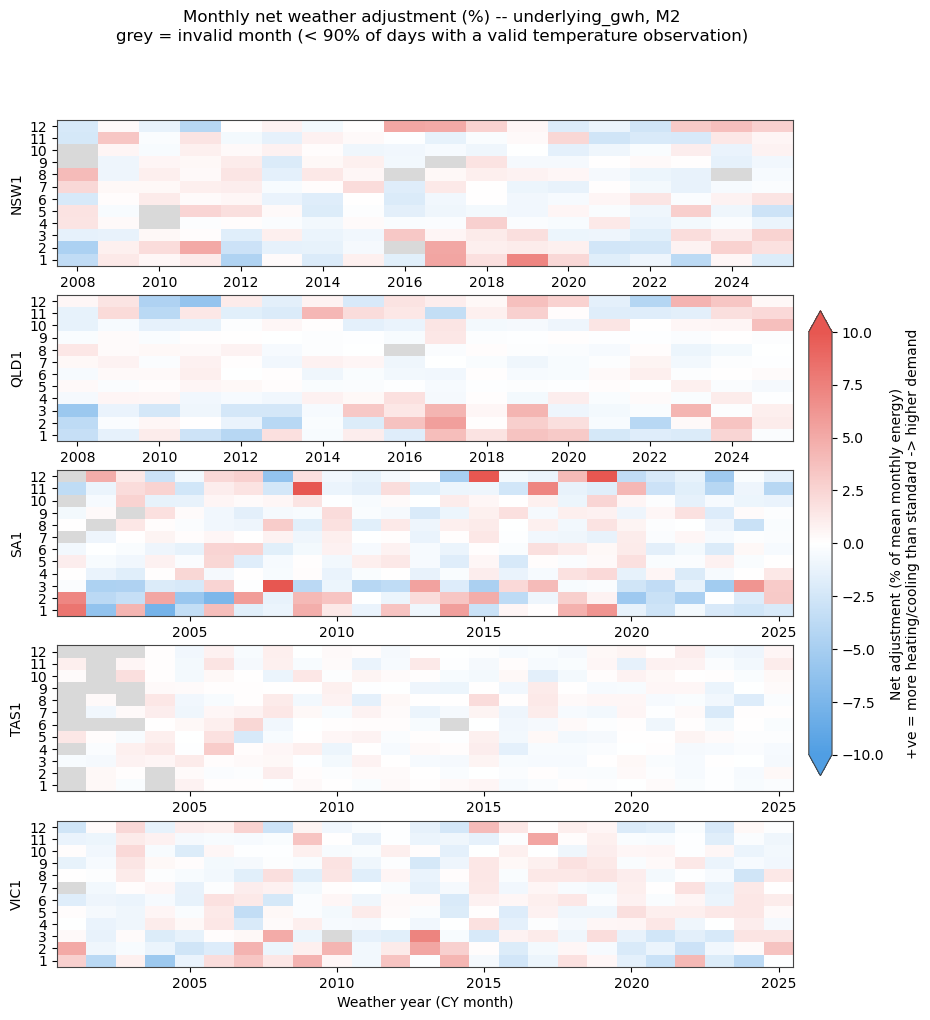

In [10]:
AKAYSHA_DIVERGING = LinearSegmentedColormap.from_list(
    'akaysha_diverging', [AKAYSHA_AZURE, '#FFFFFF', AKAYSHA_AMARANTH], N=256
)
AKAYSHA_DIVERGING.set_bad('#D9D9D9')  # invalid months: neutral grey, not part of the scale

heat_data = monthly_df[(monthly_df.dep_var == 'underlying_gwh') & (monthly_df.coef_set == 'M2')]
# Cap the shared scale at +/-10% so a few SA1 extremes (max |net_pct| ~14%) do not wash out
# every other cell; values beyond the cap saturate and the colourbar shows the extension.
VMAX_CAP = 10.0
print('max |net_pct|:', round(heat_data['net_pct'].abs().max(), 2), '-> colour scale capped at', VMAX_CAP)
vmax = VMAX_CAP

fig, axes = plt.subplots(len(REGIONS), 1, figsize=(10, 2.2 * len(REGIONS)), sharex=False)
im = None
for ax, region in zip(axes, REGIONS):
    start_y, end_y = REGION_YEARS[region]
    years = np.arange(start_y, end_y + 1)
    grid = np.full((12, len(years)), np.nan)
    sub = heat_data[heat_data.region == region]
    for _, r in sub.iterrows():
        grid[int(r['month']) - 1, int(r['weather_year']) - start_y] = r['net_pct']
    masked = np.ma.masked_invalid(grid)
    im = ax.pcolormesh(np.arange(start_y, end_y + 2) - 0.5, np.arange(1, 14) - 0.5, masked,
                        cmap=AKAYSHA_DIVERGING, vmin=-vmax, vmax=vmax, shading='flat')
    ax.set_yticks(range(1, 13))
    ax.set_ylabel(region)
    ax.set_xlim(start_y - 0.5, end_y + 0.5)
    ax.grid(False)

axes[-1].set_xlabel('Weather year (CY month)')
fig.suptitle('Monthly net weather adjustment (%) -- underlying_gwh, M2\n'
             'grey = invalid month (< 90% of days with a valid temperature observation)')
cbar = fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.03, pad=0.02, extend='both')
cbar.set_label('Net adjustment (% of mean monthly energy)\n+ve = more heating/cooling than standard -> higher demand')
fig.savefig(FIGURES_DIR / 'monthly_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

In [11]:
from PIL import Image
for fname in ['annual_adjustment.png', 'monthly_heatmap.png']:
    im = Image.open(FIGURES_DIR / fname)
    print(fname, im.size)

annual_adjustment.png (1332, 2234)
monthly_heatmap.png (1391, 1528)


## Acceptance checks (orchestrator clarification #10)

In [12]:
# (a) monthly adjustments sum to annual values (CY and FY), for every combo
for region in REGIONS:
    for dep_var in DEP_VARS:
        for coef_set in COEF_SETS:
            for _, arow in annual_df[(annual_df.region == region) & (annual_df.dep_var == dep_var)
                                      & (annual_df.coef_set == coef_set)].iterrows():
                if arow['year_type'] == 'CY':
                    msub = monthly_df[(monthly_df.region == region) & (monthly_df.dep_var == dep_var)
                                       & (monthly_df.coef_set == coef_set)
                                       & (monthly_df.weather_year == arow['year'])]
                    assert len(msub) == 12
                else:
                    months = [(arow['year'] - 1, m) for m in range(7, 13)] + [(arow['year'], m) for m in range(1, 7)]
                    frames = [monthly_df[(monthly_df.region == region) & (monthly_df.dep_var == dep_var)
                                          & (monthly_df.coef_set == coef_set)
                                          & (monthly_df.weather_year == yy) & (monthly_df.month == mm)]
                              for yy, mm in months]
                    msub = pd.concat(frames)
                    assert len(msub) == 12
                assert np.isclose(msub['HDD'].sum(), arow['HDD'], atol=1e-9)
                assert np.isclose(msub['CDD'].sum(), arow['CDD'], atol=1e-9)
                assert np.isclose(msub['heat_adj_gwh'].sum(), arow['heat_adj_gwh'], atol=1e-9)
                assert np.isclose(msub['cool_adj_gwh'].sum(), arow['cool_adj_gwh'], atol=1e-9)
                assert np.isclose(msub['net_adj_gwh'].sum(), arow['net_adj_gwh'], atol=1e-9)
print('(a) monthly sums to annual: PASSED')

(a) monthly sums to annual: PASSED


In [13]:
# (b) standards recomputed from valid years only; no invalid year contributes
for region in REGIONS:
    g_valid = dd_df[(dd_df.region == region) & (dd_df.year.isin(valid_cy[region]))]
    g_all = dd_df[dd_df.region == region]
    sm_valid = g_valid.groupby('month')[['HDD', 'CDD']].mean()
    for m in range(1, 13):
        assert np.isclose(sm_valid.loc[m, 'HDD'], std[(region, m)][0], atol=1e-9)
        assert np.isclose(sm_valid.loc[m, 'CDD'], std[(region, m)][1], atol=1e-9)
    # recompute using ALL years (including invalid) would differ if any invalid year's
    # valid months' values differ from the standard -- confirm the standard excludes them
    invalid_years = sorted(set(g_all.year.unique()) - set(valid_cy[region]))
    for y in invalid_years:
        assert y not in valid_cy[region]
    assert len(valid_cy[region]) + len(invalid_cy_reasons[region]) == len(g_all.year.unique())
print('(b) standards use valid years only, no invalid year contributes: PASSED')

(b) standards use valid years only, no invalid year contributes: PASSED


In [14]:
# (c) year/month coverage matches S7 exactly per region
for region in REGIONS:
    start_y, end_y = REGION_YEARS[region]
    years_in_csv = sorted(monthly_df[monthly_df.region == region]['weather_year'].unique())
    assert years_in_csv == list(range(start_y, end_y + 1)), (region, years_in_csv)
    assert 2026 not in years_in_csv
    if region in ('NSW1', 'QLD1'):
        assert min(years_in_csv) == 2008 and 2007 not in years_in_csv
    months_in_csv = sorted(monthly_df[monthly_df.region == region]['month'].unique())
    assert months_in_csv == list(range(1, 13))
print('(c) year/month coverage matches S7 exactly: PASSED')

(c) year/month coverage matches S7 exactly: PASSED


In [15]:
# (d) CY mean of annual HDD over valid years equals sum_m std_HDD_m (true by construction)
for region in REGIONS:
    g = dd_df[(dd_df.region == region) & (dd_df.year.isin(valid_cy[region]))]
    annual_totals = g.groupby('year')[['HDD', 'CDD']].sum()
    mean_annual = annual_totals.mean()
    assert np.isclose(mean_annual['HDD'], annual_std[region][0], atol=1e-9)
    assert np.isclose(mean_annual['CDD'], annual_std[region][1], atol=1e-9)
print('(d) CY mean of annual HDD/CDD equals sum of monthly standards: PASSED')

(d) CY mean of annual HDD/CDD equals sum of monthly standards: PASSED


## Hand-check: VIC1, 2019, CY, underlying_gwh, M2

Recomputed independently from the raw parquet rows with plain pandas, not
using `select_sample`-equivalent helper functions from the main pipeline
above.

In [16]:
region, year, dep_var, coef_set = 'VIC1', 2019, 'underlying_gwh', 'M2'

raw = df[(df.region == region) & (df.year == year)]
hand_hdd, hand_cdd = [], []
for m in range(1, 13):
    sm = raw[raw.month == m]
    dim = calendar.monthrange(year, m)[1]
    vs = sm['ok_temp'].sum() / dim
    assert vs >= 0.90, (m, vs)
    hand_hdd.append(sm.loc[sm.ok_temp, 'HDD'].mean() * dim)
    hand_cdd.append(sm.loc[sm.ok_temp, 'CDD'].mean() * dim)
hand_hdd_annual, hand_cdd_annual = sum(hand_hdd), sum(hand_cdd)

# hand-built standard: mean over valid CY years, independently re-derived from raw
valid_years_hand = []
for y in range(REGION_YEARS[region][0], REGION_YEARS[region][1] + 1):
    ok = True
    for m in range(1, 13):
        sm = raw2 = df[(df.region == region) & (df.year == y) & (df.month == m)]
        dim = calendar.monthrange(y, m)[1]
        if sm['ok_temp'].sum() / dim < 0.90:
            ok = False
            break
    if ok:
        valid_years_hand.append(y)
assert valid_years_hand == valid_cy[region]

month_stds = {}
for m in range(1, 13):
    vals_hdd, vals_cdd = [], []
    for y in valid_years_hand:
        sm = df[(df.region == region) & (df.year == y) & (df.month == m)]
        dim = calendar.monthrange(y, m)[1]
        vals_hdd.append(sm.loc[sm.ok_temp, 'HDD'].mean() * dim)
        vals_cdd.append(sm.loc[sm.ok_temp, 'CDD'].mean() * dim)
    month_stds[m] = (np.mean(vals_hdd), np.mean(vals_cdd))
hand_std_hdd_annual = sum(v[0] for v in month_stds.values())
hand_std_cdd_annual = sum(v[1] for v in month_stds.values())
assert np.isclose(hand_std_hdd_annual, annual_std[region][0])
assert np.isclose(hand_std_cdd_annual, annual_std[region][1])

b_hdd, b_cdd = coef[(region, dep_var, coef_set)]
hand_heat = b_hdd * (hand_hdd_annual - hand_std_hdd_annual)
hand_cool = b_cdd * (hand_cdd_annual - hand_std_cdd_annual)
hand_net = hand_heat + hand_cool

prim = df[(df.region == region) & (df.date >= pd.Timestamp(PRIMARY[0])) & (df.date <= pd.Timestamp(PRIMARY[1]))
          & (df['ok_underlying'])]
hand_denom = prim['underlying_gwh'].mean() * 365.25
hand_net_pct = hand_net / hand_denom * 100

csv_row = annual_df[(annual_df.region == region) & (annual_df.year == year) & (annual_df.dep_var == dep_var)
                     & (annual_df.coef_set == coef_set) & (annual_df.year_type == 'CY')].iloc[0]

print('hand :', hand_hdd_annual, hand_cdd_annual, hand_heat, hand_cool, hand_net, hand_denom, hand_net_pct)
print('csv  :', csv_row['HDD'], csv_row['CDD'], csv_row['heat_adj_gwh'], csv_row['cool_adj_gwh'],
      csv_row['net_adj_gwh'], hand_denom, csv_row['net_pct'])

assert np.isclose(hand_hdd_annual, csv_row['HDD'], atol=1e-9)
assert np.isclose(hand_cdd_annual, csv_row['CDD'], atol=1e-9)
assert np.isclose(hand_heat, csv_row['heat_adj_gwh'], atol=1e-9)
assert np.isclose(hand_cool, csv_row['cool_adj_gwh'], atol=1e-9)
assert np.isclose(hand_net, csv_row['net_adj_gwh'], atol=1e-9)
assert np.isclose(hand_net_pct, csv_row['net_pct'], atol=1e-9)
print('VIC1 2019 CY hand-check PASSED')

hand : 868.9815159574467 163.82500000000002 120.57380750554535 119.67527554068772 240.24908304623307 49459.83631172185 0.4857458110699301
csv  : 868.9815159574467 163.82500000000002 120.57380750554526 119.6752755406875 240.24908304623276 49459.83631172185 0.4857458110699295
VIC1 2019 CY hand-check PASSED


## Materiality summary

All `net_pct`-derived columns are percentages (e.g. 1.5 means 1.5% of annual or monthly energy). CY = calendar year, FY = financial year labelled by ending year (FY2025 = Jul 2024 - Jun 2025). `cy_offset_net_pct`/`fy_offset_net_pct` is the % shift implied by using the mean-based standard here vs. AEMO POE50/median convention. No recommendation is drawn here -- that is Phase 5.

| region   | dep_var        | coef_set   |   cy_net_pct_min |   cy_net_pct_max |   cy_net_pct_range |   fy_net_pct_min |   fy_net_pct_max |   fy_net_pct_range |   n_cy_years |   n_fy_years |   n_valid_months |   share_months_abs_gt_5pct |   share_months_abs_gt_2p5pct |   cy_offset_HDD |   cy_offset_CDD |   fy_offset_HDD |   fy_offset_CDD |   cy_offset_net_pct |   fy_offset_net_pct |
|:---------|:---------------|:-----------|-----------------:|-----------------:|-------------------:|-----------------:|-----------------:|-------------------:|-------------:|-------------:|-----------------:|---------------------------:|-----------------------------:|----------------:|----------------:|----------------:|----------------:|--------------------:|--------------------:|
| NSW1     | underlying_gwh | M2         |           -1.007 |            0.847 |              1.854 |           -1.1   |            1.052 |              2.152 |           13 |           11 |              208 |                      0.029 |                        0.13  |           6.625 |         -10.304 |         -13.414 |          10.432 |              -0.076 |               0.04  |
| NSW1     | underlying_gwh | M4_LR      |           -1.063 |            0.9   |              1.963 |           -1.205 |            1.113 |              2.318 |           13 |           11 |              208 |                      0.029 |                        0.159 |           6.625 |         -10.304 |         -13.414 |          10.432 |              -0.077 |               0.038 |
| NSW1     | oper_gwh       | M2         |           -0.977 |            0.831 |              1.809 |           -1.137 |            1.025 |              2.161 |           13 |           11 |              208 |                      0.029 |                        0.135 |           6.625 |         -10.304 |         -13.414 |          10.432 |              -0.07  |               0.032 |
| NSW1     | oper_gwh       | M4_LR      |           -1.098 |            0.934 |              2.032 |           -1.275 |            1.151 |              2.426 |           13 |           11 |              208 |                      0.034 |                        0.173 |           6.625 |         -10.304 |         -13.414 |          10.432 |              -0.078 |               0.036 |
| QLD1     | underlying_gwh | M2         |           -1.241 |            1.275 |              2.516 |           -1.153 |            0.896 |              2.049 |           17 |           16 |              215 |                      0.014 |                        0.14  |           2.377 |         -11.549 |           5.631 |          -5.094 |              -0.112 |              -0.037 |
| QLD1     | underlying_gwh | M4_LR      |           -1.28  |            1.315 |              2.595 |           -1.189 |            0.928 |              2.116 |           17 |           16 |              215 |                      0.014 |                        0.163 |           2.377 |         -11.549 |           5.631 |          -5.094 |              -0.116 |              -0.038 |
| QLD1     | oper_gwh       | M2         |           -1.253 |            1.283 |              2.536 |           -1.164 |            0.892 |              2.056 |           17 |           16 |              215 |                      0.014 |                        0.14  |           2.377 |         -11.549 |           5.631 |          -5.094 |              -0.111 |              -0.04  |
| QLD1     | oper_gwh       | M4_LR      |           -1.405 |            1.441 |              2.846 |           -1.305 |            1.007 |              2.312 |           17 |           16 |              215 |                      0.023 |                        0.167 |           2.377 |         -11.549 |           5.631 |          -5.094 |              -0.125 |              -0.044 |
| SA1      | underlying_gwh | M2         |           -1.895 |            1.844 |              3.738 |           -1.24  |            1.329 |              2.569 |           22 |           21 |              295 |                      0.071 |                        0.241 |           2.308 |          -0.765 |          10.823 |          11.926 |               0.001 |               0.195 |
| SA1      | underlying_gwh | M4_LR      |           -2.074 |            2.001 |              4.075 |           -1.341 |            1.427 |              2.768 |           22 |           21 |              295 |                      0.098 |                        0.268 |           2.308 |          -0.765 |          10.823 |          11.926 |               0.002 |               0.214 |
| SA1      | oper_gwh       | M2         |           -2.433 |            2.373 |              4.806 |           -1.598 |            1.716 |              3.314 |           22 |           21 |              295 |                      0.149 |                        0.319 |           2.308 |          -0.765 |          10.823 |          11.926 |               0.001 |               0.25  |
| SA1      | oper_gwh       | M4_LR      |           -2.757 |            2.691 |              5.449 |           -1.812 |            1.947 |              3.759 |           22 |           21 |              295 |                      0.173 |                        0.359 |           2.308 |          -0.765 |          10.823 |          11.926 |               0.001 |               0.283 |
| TAS1     | underlying_gwh | M2         |           -0.529 |            0.74  |              1.269 |           -0.551 |            0.481 |              1.032 |           20 |           20 |              280 |                      0     |                        0.004 |          -6.91  |           1.029 |           0.034 |          -2.226 |              -0.019 |              -0.004 |
| TAS1     | underlying_gwh | M4_LR      |           -0.563 |            0.787 |              1.35  |           -0.586 |            0.511 |              1.098 |           20 |           20 |              280 |                      0     |                        0.007 |          -6.91  |           1.029 |           0.034 |          -2.226 |              -0.021 |              -0.004 |
| TAS1     | oper_gwh       | M2         |           -0.523 |            0.72  |              1.243 |           -0.545 |            0.462 |              1.006 |           20 |           20 |              280 |                      0     |                        0.004 |          -6.91  |           1.029 |           0.034 |          -2.226 |              -0.018 |              -0.005 |
| TAS1     | oper_gwh       | M4_LR      |           -0.558 |            0.762 |              1.319 |           -0.581 |            0.485 |              1.066 |           20 |           20 |              280 |                      0     |                        0.004 |          -6.91  |           1.029 |           0.034 |          -2.226 |              -0.019 |              -0.007 |
| VIC1     | underlying_gwh | M2         |           -0.991 |            0.763 |              1.754 |           -0.567 |            1     |              1.567 |           23 |           22 |              298 |                      0.017 |                        0.101 |         -11.393 |          -9.887 |          -4.813 |          -0.687 |              -0.175 |              -0.032 |
| VIC1     | underlying_gwh | M4_LR      |           -1.06  |            0.825 |              1.885 |           -0.602 |            1.034 |              1.636 |           23 |           22 |              298 |                      0.02  |                        0.114 |         -11.393 |          -9.887 |          -4.813 |          -0.687 |              -0.186 |              -0.035 |
| VIC1     | oper_gwh       | M2         |           -1.062 |            0.804 |              1.867 |           -0.614 |            1.115 |              1.729 |           23 |           22 |              298 |                      0.034 |                        0.124 |         -11.393 |          -9.887 |          -4.813 |          -0.687 |              -0.189 |              -0.033 |
| VIC1     | oper_gwh       | M4_LR      |           -1.19  |            0.894 |              2.084 |           -0.69  |            1.27  |              1.959 |           23 |           22 |              298 |                      0.044 |                        0.141 |         -11.393 |          -9.887 |          -4.813 |          -0.687 |              -0.212 |              -0.036 |
